# Olist EDA and Data Cleaning
This notebook checks the raw data, cleans it, and saves the clean files with their original names.

## 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Read the raw files

In [2]:
customers = pd.read_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data/olist_customers_dataset.csv')
geolocation = pd.read_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data/olist_geolocation_dataset.csv')
orders = pd.read_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data/olist_orders_dataset.csv')
order_items = pd.read_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data/olist_order_items_dataset.csv')
order_payments = pd.read_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data/olist_order_payments_dataset.csv')
order_reviews = pd.read_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data/olist_order_reviews_dataset.csv')
products = pd.read_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data/olist_products_dataset.csv')
sellers = pd.read_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data/olist_sellers_dataset.csv')
translation = pd.read_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data/product_category_name_translation.csv')

In [3]:
Data = {
    'customers': customers,
    'geolocation': geolocation,
    'orders': orders,
    'order_items': order_items,
    'order_payments': order_payments,
    'order_reviews': order_reviews,
    'products': products,
    'sellers': sellers,
    'translation': translation
}

## 3. Inspect all tables

Shape and first rows

In [4]:
for name in Data:
    print(f"\n===== {name} =====")
    print("Shape:", Data[name].shape)
    display(Data[name].head(3))


===== customers =====
Shape: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP



===== geolocation =====
Shape: (1000163, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP



===== orders =====
Shape: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


... (8 outputs left out)


===== sellers =====
Shape: (3095, 4)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ



===== translation =====
Shape: (71, 2)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


Data types and missing values

In [5]:
for name in Data:
    print(f"\n===== {name} =====")
    Data[name].info()
    nulls = Data[name].isnull().sum()
    display(nulls[nulls > 0])


===== customers =====
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


Series([], dtype: int64)


===== geolocation =====
<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 38.2 MB


Series([], dtype: int64)


===== orders =====
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

... (8 outputs left out)


===== sellers =====
<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 96.8 KB


Series([], dtype: int64)


===== translation =====
<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   product_category_name          71 non-null     str  
 1   product_category_name_english  71 non-null     str  
dtypes: str(2)
memory usage: 1.2 KB


Series([], dtype: int64)

Duplicated rows

In [6]:
for name in Data:
    print(name, ":", Data[name].duplicated().sum(), "duplicated rows")

customers : 0 duplicated rows
geolocation : 261831 duplicated rows
orders : 0 duplicated rows
order_items : 0 duplicated rows
order_payments : 0 duplicated rows
order_reviews : 0 duplicated rows
products : 0 duplicated rows
sellers : 0 duplicated rows
translation : 0 duplicated rows


Numeric columns

In [7]:
for name in Data:
    print(f"\n===== {name} =====")
    display(Data[name].describe())


===== customers =====


,customer_zip_code_prefix
count,99441.000000
mean,35137.474583
std,29797.938996
min,1003.000000
25%,11347.000000
50%,24416.000000
75%,58900.000000
max,99990.000000



===== geolocation =====


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06,1.000163e+06
mean,3.657417e+04,-2.117615e+01,-4.639054e+01
std,3.054934e+04,5.715866e+00,4.269748e+00
min,1.001000e+03,-3.660537e+01,-1.014668e+02
25%,1.107500e+04,-2.360355e+01,-4.857317e+01
50%,2.653000e+04,-2.291938e+01,-4.663788e+01
75%,6.350400e+04,-1.997962e+01,-4.376771e+01
max,9.999000e+04,4.506593e+01,1.211054e+02



===== orders =====


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


... (8 outputs left out)


===== sellers =====


,seller_zip_code_prefix
count,3095.000000
mean,32291.059451
std,32713.453830
min,1001.000000
25%,7093.500000
50%,14940.000000
75%,64552.500000
max,99730.000000



===== translation =====


,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


Text columns

In [8]:
for name in Data:
    text_cols = Data[name].select_dtypes(exclude='number').columns
    if len(text_cols) > 0:
        print(f"\n===== {name} =====")
        display(Data[name][text_cols].describe())


===== customers =====


,customer_id,customer_unique_id,customer_city,customer_state
count,99441,99441,99441,99441
unique,99441,96096,4119,27
top,06b8999e2fba1a1fbc88172c00ba8bc7,8d50f5eadf50201ccdcedfb9e2ac8455,sao paulo,SP
freq,1,17,15540,41746



===== geolocation =====


,geolocation_city,geolocation_state
count,1000163,1000163
unique,8011,27
top,sao paulo,SP
freq,135800,404268



===== orders =====


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2018-03-31 15:08:21,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


... (8 outputs left out)


===== sellers =====


,seller_id,seller_city,seller_state
count,3095,3095,3095
unique,3095,611,23
top,3442f8959a84dea7ee197c632cb2df15,sao paulo,SP
freq,1,694,1849



===== translation =====


,product_category_name,product_category_name_english
count,71,71
unique,71,71
top,beleza_saude,health_beauty
freq,1,1


## 4. Check categories, invalid values, and outliers

In [9]:
print('Order statuses:')
print(orders['order_status'].value_counts(dropna=False))

print('Payment types:')
print(order_payments['payment_type'].value_counts(dropna=False))

print('Review scores:')
print(order_reviews['review_score'].value_counts(dropna=False).sort_index())

print('Top product categories:')
print(products['product_category_name'].value_counts().head(10))

print('Negative prices:', (order_items['price'] < 0).sum())
print('Negative freight:', (order_items['freight_value'] < 0).sum())
print('Review scores outside 1 to 5:', (~order_reviews['review_score'].between(1, 5)).sum())

q1 = order_items['price'].quantile(0.25)
q3 = order_items['price'].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
print('Prices above the IQR limit:', (order_items['price'] > upper_limit).sum())

Order statuses:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
Payment types:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64
Review scores:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64
Top product categories:
product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64
Negative prices: 0
Negative freight: 0
Review scores outside 1 to 5: 0
Prices above the IQR limit: 8427


Keys and relationships (0 means OK)

In [10]:
print("customers customer_id unique:", customers['customer_id'].is_unique)
print("orders order_id unique:", orders['order_id'].is_unique)
print("products product_id unique:", products['product_id'].is_unique)
print("sellers seller_id unique:", sellers['seller_id'].is_unique)

print("order_items -> orders:", (~order_items['order_id'].isin(orders['order_id'])).sum())
print("order_items -> products:", (~order_items['product_id'].isin(products['product_id'])).sum())
print("order_items -> sellers:", (~order_items['seller_id'].isin(sellers['seller_id'])).sum())
print("orders -> customers:", (~orders['customer_id'].isin(customers['customer_id'])).sum())

customers customer_id unique: True
orders order_id unique: True
products product_id unique: True
sellers seller_id unique: True
order_items -> orders: 0
order_items -> products: 0
order_items -> sellers: 0
orders -> customers: 0


## 5. EDA charts

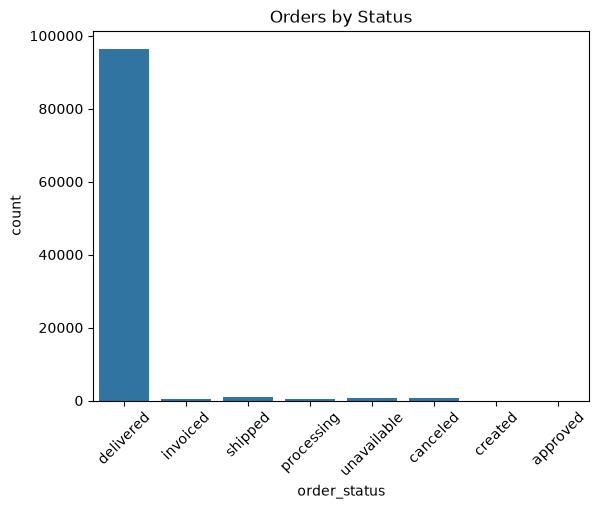

In [11]:
sns.countplot(data=orders, x='order_status')
plt.xticks(rotation=45)
plt.title('Orders by Status')
plt.show()

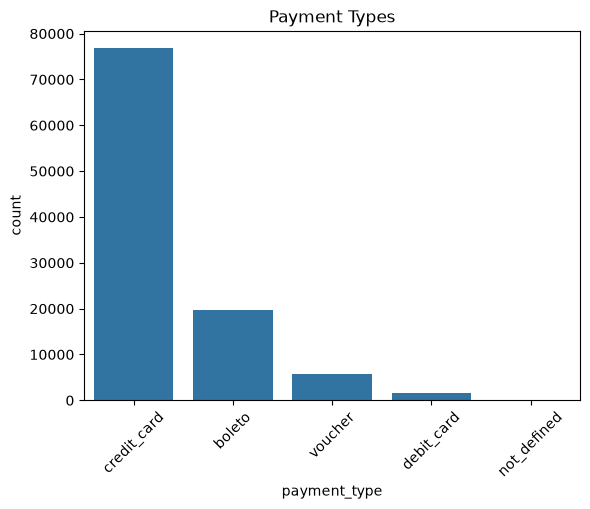

In [12]:
sns.countplot(data=order_payments, x='payment_type')
plt.xticks(rotation=45)
plt.title('Payment Types')
plt.show()

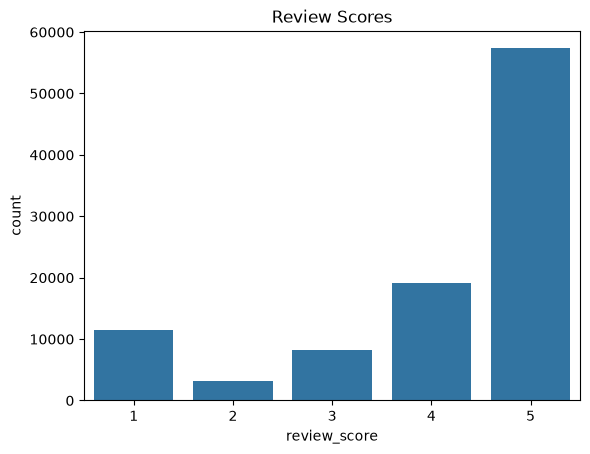

In [13]:
sns.countplot(data=order_reviews, x='review_score')
plt.title('Review Scores')
plt.show()

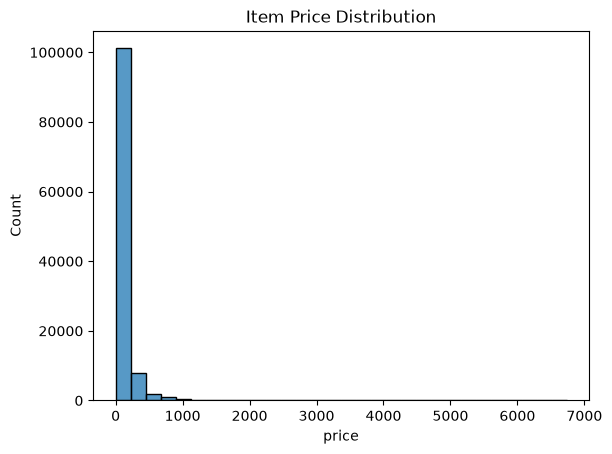

In [14]:
sns.histplot(data=order_items, x='price', bins=30)
plt.title('Item Price Distribution')
plt.show()

## 6. Clean the data

Steps for every table: remove duplicates, fill missing numbers with the median, fill missing text with 'Unknown', and remove extra spaces.

In [15]:
for name in Data:
    table = Data[name]

    # Remove duplicate rows
    table.drop_duplicates(inplace=True)

    # Fill missing numbers with the median
    num_cols = table.select_dtypes(include='number').columns
    table[num_cols] = table[num_cols].fillna(table[num_cols].median())

    # Fill missing text with 'Unknown' and remove extra spaces
    text_cols = table.select_dtypes(exclude='number').columns
    table[text_cols] = table[text_cols].fillna('Unknown')
    for col in text_cols:
        table[col] = table[col].str.strip()

In [16]:
# Make text values lowercase
orders['order_status'] = orders['order_status'].str.lower()
order_payments['payment_type'] = order_payments['payment_type'].str.lower()

In [17]:
# Convert dates ('Unknown' becomes empty date)
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'], errors='coerce')
orders['order_approved_at'] = pd.to_datetime(orders['order_approved_at'], errors='coerce')
orders['order_delivered_carrier_date'] = pd.to_datetime(orders['order_delivered_carrier_date'], errors='coerce')
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'], errors='coerce')
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'], errors='coerce')

order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'], errors='coerce')

order_reviews['review_creation_date'] = pd.to_datetime(order_reviews['review_creation_date'], errors='coerce')
order_reviews['review_answer_timestamp'] = pd.to_datetime(order_reviews['review_answer_timestamp'], errors='coerce')

## 7. Validate and save the clean files

In [18]:
for name in Data:
    print(name, 'rows and columns:', Data[name].shape)
    print('Remaining missing values:', Data[name].isnull().sum().sum())
    print('Remaining duplicate rows:', Data[name].duplicated().sum())

print('Duplicate review IDs:', order_reviews['review_id'].duplicated().sum())
print('Duplicate order IDs in reviews:', order_reviews['order_id'].duplicated().sum())
print('Repeated geolocation ZIP prefixes:', geolocation['geolocation_zip_code_prefix'].duplicated().sum())

customers rows and columns: (99441, 5)
Remaining missing values: 0
Remaining duplicate rows: 0
geolocation rows and columns: (738332, 5)
Remaining missing values: 0
Remaining duplicate rows: 0
orders rows and columns: (99441, 8)
Remaining missing values: 4908
Remaining duplicate rows: 0
order_items rows and columns: (112650, 7)
Remaining missing values: 0
Remaining duplicate rows: 0
order_payments rows and columns: (103886, 5)
Remaining missing values: 0
Remaining duplicate rows: 0
order_reviews rows and columns: (99224, 7)
Remaining missing values: 0
Remaining duplicate rows: 0
products rows and columns: (32951, 9)
Remaining missing values: 0
Remaining duplicate rows: 0
sellers rows and columns: (3095, 4)
Remaining missing values: 0
Remaining duplicate rows: 0
translation rows and columns: (71, 2)
Remaining missing values: 0
Remaining duplicate rows: 0
Duplicate review IDs: 814
Duplicate order IDs in reviews: 551
Repeated geolocation ZIP prefixes: 719317


In [19]:
customers.to_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/customers.csv', index=False)
geolocation.to_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/geolocation.csv', index=False)
orders.to_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/orders.csv', index=False)
order_items.to_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/order_items.csv', index=False)
order_payments.to_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/order_payments.csv', index=False)
order_reviews.to_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/order_reviews.csv', index=False)
products.to_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/products.csv', index=False)
sellers.to_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/sellers.csv', index=False)
translation.to_csv('C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/product_category_name_translation.csv', index=False)

print('Cleaned files saved')

Cleaned files saved
